# Bài tập E2: Transformer — Multi-Head Self-Attention (MSA) và Tokenization trên Fashion-MNIST
**Môn học:** Học sâu và Ứng dụng trong Thị giác Máy tính (CO5085)  
**Sinh viên:** Nguyễn Trần Phước (MSSV: 2470576)

## 1. Thiết lập Môi trường

In [1]:
import os
import math
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "./outputs_e2"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Device: {device}")

Device: cuda


## 2. Tải dữ liệu Fashion-MNIST & Chia tập Train / Val / Test

In [2]:
BATCH_SIZE = 64
VAL_RATIO = 0.1
DATA_DIR = "./data"

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_ds = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True, transform=transform)

val_size = int(len(full_train_ds) * VAL_RATIO)
train_size = len(full_train_ds) - val_size
generator = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(full_train_ds, [train_size, val_size], generator=generator)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

Train: 54,000 | Val: 6,000 | Test: 10,000


## 3. Hiện thực Multi-Head Self-Attention (MSA) và Transformer Encoder Block

In [3]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model: int = 64, num_heads: int = 4, attn_dropout: float = 0.1, proj_dropout: float = 0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.attn_drop = nn.Dropout(attn_dropout)
        self.proj_drop = nn.Dropout(proj_dropout)

    def forward(self, x: torch.Tensor, mask: torch.Tensor = None, return_attn: bool = False):
        B, n, _ = x.shape
        Q = self.W_q(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(x).view(B, n, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores + mask

        attn_weights = torch.softmax(scores, dim=-1)
        context = torch.matmul(self.attn_drop(attn_weights), V)
        context = context.transpose(1, 2).contiguous().view(B, n, self.d_model)
        out = self.proj_drop(self.W_o(context))

        if return_attn:
            return out, attn_weights
        return out


class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model: int = 64, num_heads: int = 4, d_ff: int = 256, dropout: float = 0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.msa = MultiHeadSelfAttention(d_model, num_heads, dropout, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor, return_attn: bool = False):
        if return_attn:
            msa_out, attn = self.msa(self.norm1(x), return_attn=True)
            x = x + msa_out
            x = x + self.ffn(self.norm2(x))
            return x, attn
        x = x + self.msa(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

test_msa = MultiHeadSelfAttention(d_model=64, num_heads=4)
test_x = torch.randn(2, 50, 64)
test_out, test_attn = test_msa(test_x, return_attn=True)
print(f"Input: {tuple(test_x.shape)} -> Output: {tuple(test_out.shape)} | Attn: {tuple(test_attn.shape)} | Row sum: {test_attn[0, 0, 0].sum().item():.4f}")

Input: (2, 50, 64) -> Output: (2, 50, 64) | Attn: (2, 4, 50, 50) | Row sum: 1.0000


## 4. Ba Phương pháp Tokenization (Patch, Pixel, CNN-Stem) & ViT Classifier

In [4]:
class PatchTokenizer(nn.Module):
    def __init__(self, patch_size: int = 4, d_model: int = 64):
        super().__init__()
        self.num_tokens = (28 // patch_size) ** 2
        self.proj = nn.Conv2d(1, d_model, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.proj(x).flatten(2).transpose(1, 2)


class PixelTokenizer(nn.Module):
    def __init__(self, downsample: int = 2, d_model: int = 64):
        super().__init__()
        self.pool = nn.AvgPool2d(kernel_size=downsample, stride=downsample) if downsample > 1 else nn.Identity()
        eff_size = 28 // downsample
        self.num_tokens = eff_size * eff_size
        self.proj = nn.Linear(1, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.pool(x).flatten(2).transpose(1, 2)
        return self.proj(x)


class CNNStemTokenizer(nn.Module):
    def __init__(self, d_model: int = 64):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.Conv2d(32, d_model, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(d_model),
            nn.GELU()
        )
        self.num_tokens = 7 * 7

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.stem(x).flatten(2).transpose(1, 2)


class VisionTransformerClassifier(nn.Module):
    def __init__(
        self,
        tokenizer_type: str = "patch",
        num_classes: int = 10,
        d_model: int = 64,
        num_heads: int = 4,
        num_layers: int = 2,
        d_ff: int = 256,
        dropout: float = 0.1
    ):
        super().__init__()
        tok = tokenizer_type.lower()
        if tok == "patch":
            self.tokenizer = PatchTokenizer(patch_size=4, d_model=d_model)
        elif tok == "pixel":
            self.tokenizer = PixelTokenizer(downsample=2, d_model=d_model)
        elif tok == "cnn_stem":
            self.tokenizer = CNNStemTokenizer(d_model=d_model)
        else:
            raise ValueError(f"Unknown tokenizer: {tokenizer_type}")

        self.num_tokens = self.tokenizer.num_tokens
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_tokens + 1, d_model))
        self.pos_drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(d_model=d_model, num_heads=num_heads, d_ff=d_ff, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x: torch.Tensor, return_attn: bool = False):
        B = x.size(0)
        tokens = self.tokenizer(x)
        tokens = torch.cat([self.cls_token.expand(B, -1, -1), tokens], dim=1)
        x_seq = self.pos_drop(tokens + self.pos_embed)

        attn_maps = []
        for blk in self.blocks:
            if return_attn:
                x_seq, attn = blk(x_seq, return_attn=True)
                attn_maps.append(attn)
            else:
                x_seq = blk(x_seq)

        x_seq = self.norm(x_seq)
        logits = self.head(x_seq[:, 0])
        if return_attn:
            return logits, attn_maps
        return logits


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for tok in ["patch", "pixel", "cnn_stem"]:
    m = VisionTransformerClassifier(tokenizer_type=tok)
    seq_n = m.num_tokens + 1
    print(f"Tokenizer: {tok.upper():<10} | Seq Len (n): {seq_n:<4} | Attn Matrix: {seq_n}x{seq_n:<4} | Params: {count_parameters(m):,}")

Tokenizer: PATCH      | Seq Len (n): 50   | Attn Matrix: 50x50   | Params: 105,098
Tokenizer: PIXEL      | Seq Len (n): 197  | Attn Matrix: 197x197  | Params: 113,546
Tokenizer: CNN_STEM   | Seq Len (n): 50   | Attn Matrix: 50x50   | Params: 122,922


## 5. Huấn luyện và Đánh giá 3 Phương pháp Tokenization

In [5]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

EPOCHS = 15
LR = 1e-3
tokenizers_to_run = ["patch", "pixel", "cnn_stem"]
history, trained_models, test_predictions, summary_results = {}, {}, {}, []

for tok_name in tokenizers_to_run:
    print(f"\n{'='*55}\nTraining ViT Tokenizer: {tok_name.upper()}\n{'='*55}")
    model = VisionTransformerClassifier(
        tokenizer_type=tok_name, num_classes=len(CLASS_NAMES),
        d_model=64, num_heads=4, num_layers=2
    ).to(device)
    num_params = count_parameters(model)
    seq_len = model.num_tokens + 1

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state = 0.0, None
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)
        scheduler.step()

        h["train_loss"].append(tr_loss)
        h["val_loss"].append(va_loss)
        h["train_acc"].append(tr_acc)
        h["val_acc"].append(va_acc)

        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] "
              f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc*100:.2f}% | "
              f"Val Loss: {va_loss:.4f} | Val Acc: {va_acc*100:.2f}%")

    train_time = time.time() - start_time
    history[tok_name] = h

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    trained_models[tok_name] = model
    test_loss, test_acc, preds, labels = evaluate(model, test_loader, criterion, device)
    test_predictions[tok_name] = (preds, labels)
    print(f"--> Test ({tok_name.upper()}): Loss = {test_loss:.4f} | Acc = {test_acc*100:.2f}% | Time = {train_time:.1f}s")

    summary_results.append({
        "Tokenizer": tok_name.upper(),
        "Sequence Length (n)": seq_len,
        "Trainable Params": num_params,
        "Best Val Acc (%)": round(best_val_acc * 100, 2),
        "Test Acc (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Train Time (s)": round(train_time, 1)
    })


Training ViT Tokenizer: PATCH
Epoch [01/15] Train Loss: 0.8871 | Train Acc: 67.01% | Val Loss: 0.5307 | Val Acc: 80.92%
Epoch [02/15] Train Loss: 0.5404 | Train Acc: 80.31% | Val Loss: 0.4635 | Val Acc: 83.12%
Epoch [03/15] Train Loss: 0.4765 | Train Acc: 82.62% | Val Loss: 0.4738 | Val Acc: 83.22%
Epoch [04/15] Train Loss: 0.4414 | Train Acc: 83.79% | Val Loss: 0.4210 | Val Acc: 84.62%
Epoch [05/15] Train Loss: 0.4126 | Train Acc: 84.83% | Val Loss: 0.4109 | Val Acc: 84.97%
Epoch [06/15] Train Loss: 0.3933 | Train Acc: 85.59% | Val Loss: 0.3793 | Val Acc: 86.23%
Epoch [07/15] Train Loss: 0.3744 | Train Acc: 86.30% | Val Loss: 0.3632 | Val Acc: 86.92%
Epoch [08/15] Train Loss: 0.3580 | Train Acc: 86.73% | Val Loss: 0.3507 | Val Acc: 86.72%
Epoch [09/15] Train Loss: 0.3420 | Train Acc: 87.41% | Val Loss: 0.3434 | Val Acc: 87.78%
Epoch [10/15] Train Loss: 0.3295 | Train Acc: 87.72% | Val Loss: 0.3333 | Val Acc: 87.77%
Epoch [11/15] Train Loss: 0.3182 | Train Acc: 88.15% | Val Loss: 0.33

## 6. Kết quả So sánh & Biểu đồ Learning Curves

,Tokenizer,Sequence Length (n),Trainable Params,Best Val Acc (%),Test Acc (%),Test Loss,Train Time (s)
0,PATCH,50,105098,88.55,88.30,0.3278,317.1
1,PIXEL,197,113546,86.20,84.72,0.3998,315.7
2,CNN_STEM,50,122922,90.87,90.33,0.2828,287.4


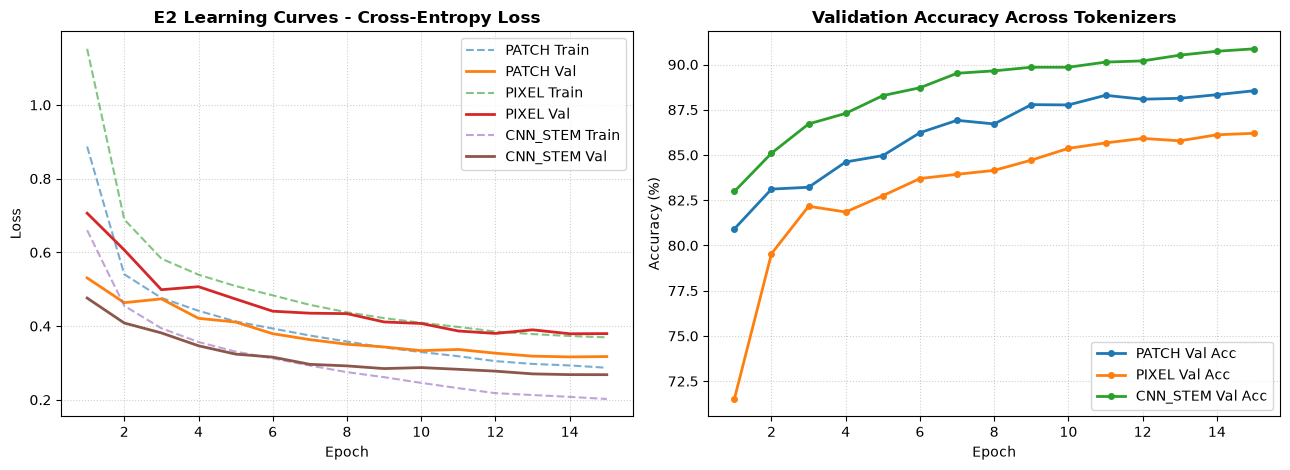

In [6]:
df_summary = pd.DataFrame(summary_results)
display(df_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, h in history.items():
    axes[0].plot(range(1, EPOCHS + 1), h["train_loss"], linestyle="--", alpha=0.6, label=f"{name.upper()} Train")
    axes[0].plot(range(1, EPOCHS + 1), h["val_loss"], linewidth=2, label=f"{name.upper()} Val")
    axes[1].plot(range(1, EPOCHS + 1), [a * 100 for a in h["val_acc"]], linewidth=2, marker="o", markersize=4, label=f"{name.upper()} Val Acc")

axes[0].set_title("E2 Learning Curves - Cross-Entropy Loss", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

axes[1].set_title("Validation Accuracy Across Tokenizers", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "e2_learning_curves_fashion_mnist.png"), dpi=150)
plt.show()

## 7. Trực quan hóa [CLS] Attention Maps

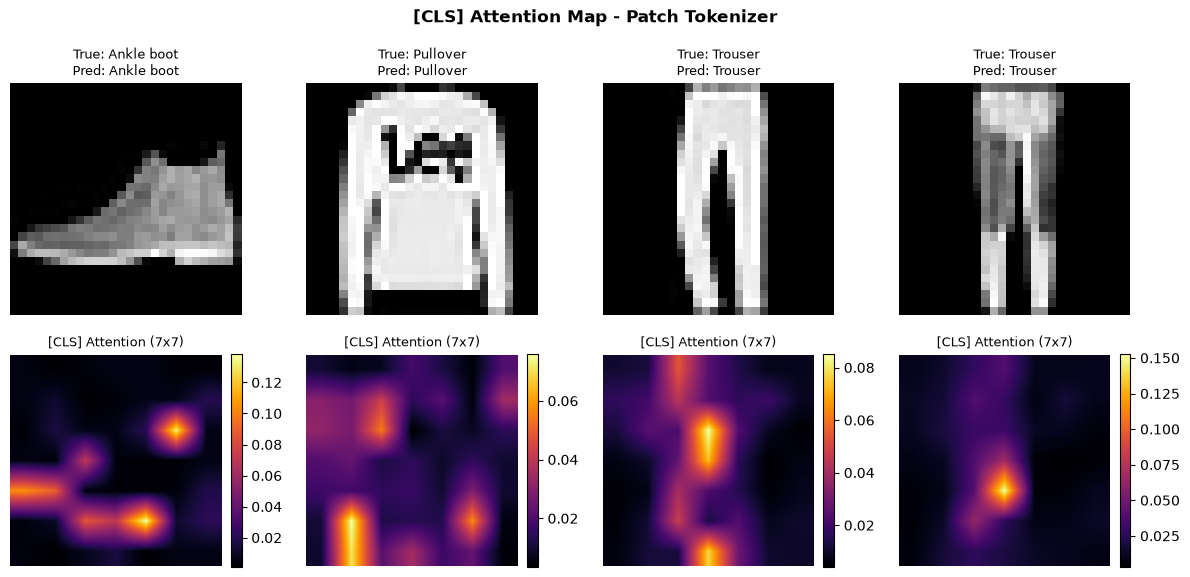

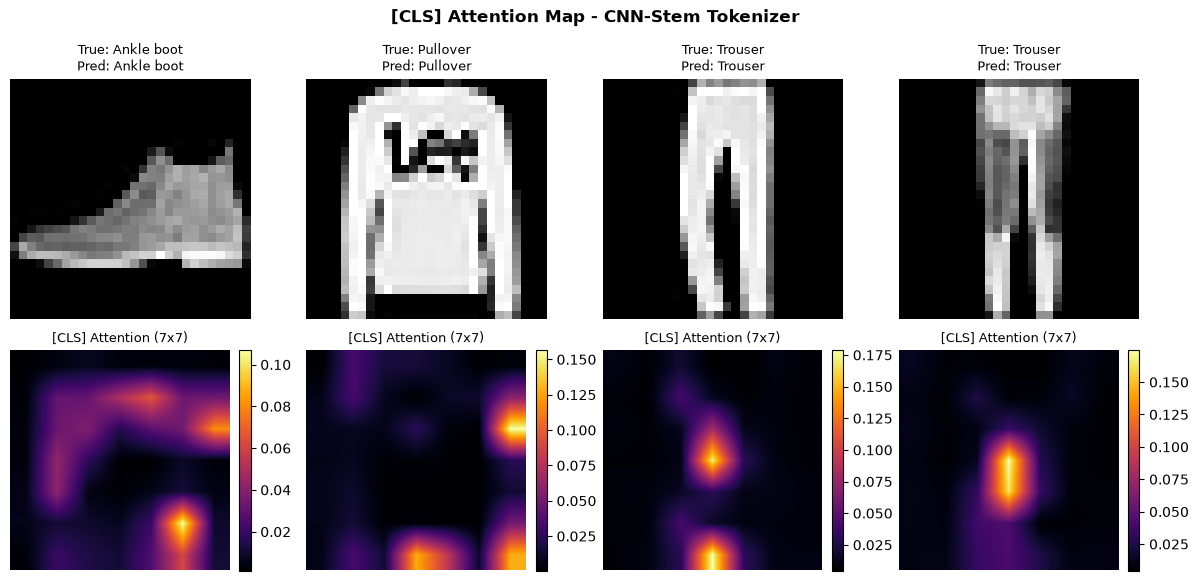

In [7]:
@torch.no_grad()
def visualize_cls_attention(model, test_loader, device, title_prefix, save_path):
    model.eval()
    images, labels = next(iter(test_loader))
    images = images[:4].to(device)
    labels = labels[:4]

    logits, attn_maps = model(images, return_attn=True)
    preds = logits.argmax(dim=1).cpu()

    last_attn = attn_maps[-1].mean(dim=1).cpu()
    grid_size = int(math.sqrt(model.num_tokens))

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i in range(4):
        img_np = images[i].cpu().squeeze(0).numpy() * 0.5 + 0.5
        axes[0, i].imshow(img_np, cmap="gray")
        axes[0, i].set_title(f"True: {CLASS_NAMES[labels[i]]}\nPred: {CLASS_NAMES[preds[i]]}", fontsize=9)
        axes[0, i].axis("off")

        cls_attn = last_attn[i, 0, 1:].reshape(grid_size, grid_size).numpy()
        im = axes[1, i].imshow(cls_attn, cmap="inferno", interpolation="bilinear")
        axes[1, i].set_title(f"[CLS] Attention ({grid_size}x{grid_size})", fontsize=9)
        axes[1, i].axis("off")
        plt.colorbar(im, ax=axes[1, i], fraction=0.046, pad=0.04)

    plt.suptitle(f"[CLS] Attention Map - {title_prefix}", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()

visualize_cls_attention(
    trained_models["patch"], test_loader, device,
    title_prefix="Patch Tokenizer",
    save_path=os.path.join(OUTPUT_DIR, "attn_map_patch_fashion_mnist.png")
)

visualize_cls_attention(
    trained_models["cnn_stem"], test_loader, device,
    title_prefix="CNN-Stem Tokenizer",
    save_path=os.path.join(OUTPUT_DIR, "attn_map_cnn_stem_fashion_mnist.png")
)

In [8]:
import json

# 1. Lưu Config & Seed để tái lập
config_e2 = {
    "dataset": "Fashion-MNIST",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "val_ratio": VAL_RATIO,
    "epochs": EPOCHS,
    "learning_rate": LR,
    "weight_decay": 1e-2,
    "optimizer": "AdamW",
    "scheduler": "CosineAnnealingLR",
    "grad_clip_max_norm": 1.0,
    "d_model": 64,
    "num_heads": 4,
    "num_layers": 2,
    "d_ff": 256,
    "dropout": 0.1,
    "device": str(device)
}
with open(os.path.join(OUTPUT_DIR, "config_e2.json"), "w", encoding="utf-8") as f:
    json.dump(config_e2, f, indent=4, ensure_ascii=False)

# 2. Lưu Log lịch sử huấn luyện từng Epoch
with open(os.path.join(OUTPUT_DIR, "training_log_e2.json"), "w", encoding="utf-8") as f:
    json.dump(history, f, indent=4)

# 3. Lưu Bảng tổng hợp số liệu ra CSV
df_summary.to_csv(os.path.join(OUTPUT_DIR, "summary_results_e2.csv"), index=False)
print("Đã lưu thành công config_e2.json, training_log_e2.json và summary_results_e2.csv!")

Đã lưu thành công config_e2.json, training_log_e2.json và summary_results_e2.csv!
